### 1. Imports and Setup

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Adjust animation embedding limit to prevent the 20MB limit warning
plt.rcParams['animation.embed_limit'] = 50.0

### 2. Load and Explore the Dataset

Dataset Shape: (100, 3)


,cgpa,resume_score,placed
0,8.14,6.52,1
1,6.17,5.17,0
2,8.27,8.86,1
3,6.88,7.27,1
4,7.52,7.30,1


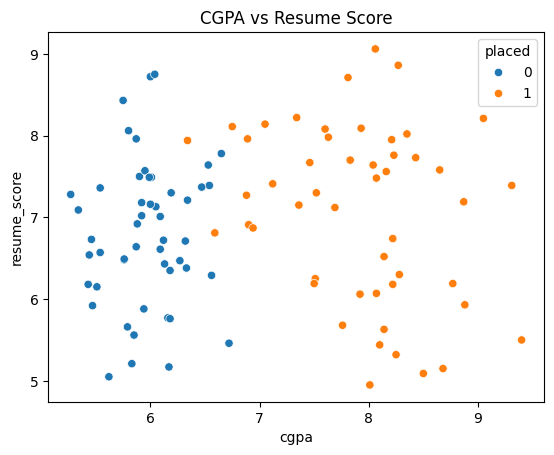

In [4]:
df = pd.read_csv("placement.csv")
print("Dataset Shape:", df.shape)
display(df.head())

sns.scatterplot(x=df['cgpa'], y=df['resume_score'], hue=df['placed'])
plt.title("CGPA vs Resume Score")
plt.show()

### 3. Training with Scikit-Learn's Perceptron

Weights (w1, w2): [[ 40.26 -36.  ]]
Bias: [-25.]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but Perceptron was fitted with feature names
  warnings.warn(


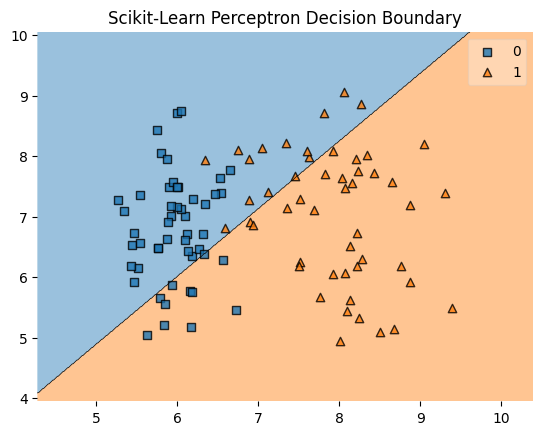

In [5]:
from sklearn.linear_model import Perceptron
from mlxtend.plotting import plot_decision_regions

X_sk = df[['cgpa', 'resume_score']]
y_sk = df['placed']

p = Perceptron()
p.fit(X_sk, y_sk)

print("Weights (w1, w2):", p.coef_)
print("Bias:", p.intercept_)

# Visualize decision boundary from Scikit-Learn's model
plot_decision_regions(X_sk.values, y_sk.values, clf=p)
plt.title("Scikit-Learn Perceptron Decision Boundary")
plt.show()

### 4. Custom Perceptron Implementation (with Bias Column)

In [11]:
import numpy as np
import pandas as pd

# Standardize the features (CGPA & Resume Score) for optimal convergence
cgpa_mean, cgpa_std = df['cgpa'].mean(), df['cgpa'].std()
resume_mean, resume_std = df['resume_score'].mean(), df['resume_score'].std()

# Create a scaled copy of the dataframe features
df_scaled = df.copy()
df_scaled['cgpa'] = (df['cgpa'] - cgpa_mean) / cgpa_std
df_scaled['resume_score'] = (df['resume_score'] - resume_mean) / resume_std

X = df_scaled[["cgpa", "resume_score"]]
y = df_scaled["placed"]

class SimplePerceptron:
    def __init__(self, learning_rate=0.01, epochs=1000):
        self.lr = learning_rate
        self.epochs = epochs
        self.weights_ = None
        self.intercept_ = None
        self.weight_history = []

    def _step(self, z):
        return 1 if z >= 0 else 0

    def fit(self, X, y):
        # Convert inputs to numpy arrays
        X_arr = np.array(X)
        y_arr = np.array(y)

        # Initialize weights for features + 1 for bias (intercept)
        num_features = X_arr.shape[1]
        w = np.zeros(num_features + 1)
        self.weight_history = []

        for epoch in range(self.epochs):
            errors = 0
            for j in range(len(X_arr)):
                # Append 1 to the features for the bias term calculation
                x_j = np.insert(X_arr[j], 0, 1)
                z = np.dot(x_j, w)
                y_hat = self._step(z)

                if y_arr[j] != y_hat:
                    w = w + self.lr * (y_arr[j] - y_hat) * x_j
                    errors += 1

                self.weight_history.append(w.copy())

            if errors == 0:
                break

        self.intercept_ = w[0]
        self.weights_ = w[1:]
        return self

    def predict(self, X_eval):
        X_eval_arr = np.array(X_eval)
        predictions = []
        for x in X_eval_arr:
            z = np.dot(x, self.weights_) + self.intercept_
            predictions.append(self._step(z))
        return np.array(predictions)

# Train the clean OOP Custom Perceptron
model = SimplePerceptron(learning_rate=0.01, epochs=1000)
model.fit(X, y)

# Expose historical weights for animation compatibility
weight_history = model.weight_history
b = model.intercept_
weights = model.weights_

print("Trained Custom Weights (on scaled data):", weights)
print("Trained Custom Bias (on scaled data):", b)

Trained Custom Weights (on scaled data): [0.05092922 0.01296437]
Trained Custom Bias (on scaled data): -3.469446951953614e-18


### 4.1. Visualize Custom Perceptron Decision Boundary

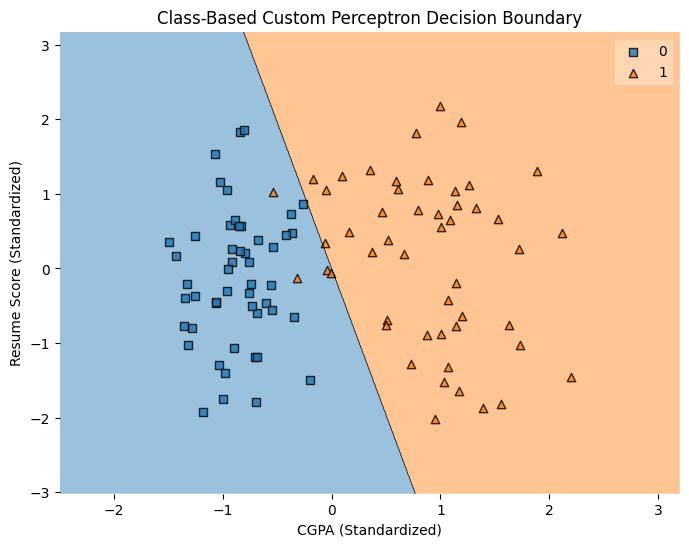

In [12]:
from mlxtend.plotting import plot_decision_regions
import matplotlib.pyplot as plt

# Plot decision boundary directly using our model instance
plt.figure(figsize=(8, 6))
plot_decision_regions(X.values, y.values, clf=model)
plt.title("Class-Based Custom Perceptron Decision Boundary")
plt.xlabel("CGPA (Standardized)")
plt.ylabel("Resume Score (Standardized)")
plt.show()

### 5. Animate Perceptron Learning Process

In [8]:
def animate(X, y):
    fig, ax = plt.subplots()
    ax.scatter(X["cgpa"], X["resume_score"], c=y, cmap="bwr")
    ax.set_xlabel("CGPA")
    ax.set_ylabel("Resume Score")

    x_min, x_max = X["cgpa"].min() - 0.5, X["cgpa"].max() + 0.5
    y_min, y_max = X["resume_score"].min() - 0.5, X["resume_score"].max() + 0.5
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

    line, = ax.plot([], [], lw=2, color='green')

    def update(frame):
        w = weight_history[frame]
        w0, w1, w2 = w[0], w[1], w[2]
        x_vals = np.array([x_min, x_max])

        if abs(w2) > 1e-10:
            y_vals = -(w0 + w1 * x_vals) / w2
            line.set_data(x_vals, y_vals)

        ax.set_title(f"Iteration: {frame + 1}")
        return line,

    # We only take a subset of history frames to speed up rendering if history is very large
    step_size = max(1, len(weight_history) // 100)
    frames_to_show = list(range(0, len(weight_history), step_size))
    if (len(weight_history) - 1) not in frames_to_show:
        frames_to_show.append(len(weight_history) - 1)

    ani = FuncAnimation(
        fig,
        update,
        frames=frames_to_show,
        interval=50,
        blit=True
    )
    plt.close(fig)
    return ani

ani = animate(X, y)
HTML(ani.to_jshtml())